# Tutorial

This tutorial shows how to use the package's main functionalities:
1. [Loading files and data structures](##1.-Loading-files-and-data-structures)
2. [Distance functions for dynamic models and heatmaps](##2.-Distance-functions-for-dynamic-models-and-heatmaps)
3. [Clustering algorithms](##3.-Clustering-algorithms)
4. [Dimensionality reduction algorithms](##-4.-Dimensionality-reduction-algorithms)

<break>

# Background on the sample data

<b><i>Scifate data</i></b>
- Sci-fate is a high-throughput sequencing method designed to track transcriptional dynamics of cells (i.e cells which are newly synthesized within a specific window of time) as compared to traditional methods which only observe a "static snapshot" of the cell at a specific moment
- By labelling new mRNA with the 4sU molecule, "old" and "new" genetic activity in the cell can be tracked over a 10-hour response
- Link to [original paper](https://www.nature.com/articles/s41587-020-0480-9) to learn more

<br>

| File name | Description | Information | Dataset size (gene x cell) | 
| --------- | ----------- | ------------ | ------------ |
matrix.mtx.gz | Gene expression matrix | Dataset showing the activity levels of all genes across all individual cells | (43750, 7404) |
4sU.Binom.ntr.mtx.gz | New to Total Ratio matrix | The proportion of a gene's total expression that is "new” | (43750, 7404) |
barcodes.tsv.gz | Barcodes + metadata | Unique molecular tags used to identify cells | (7404, 1) |
features.tsv.gz | Features + metadata | Metadata on genes measured | (43750, 5) |
trajectories_sci.csv | Trajectory table | Trajectory of how cells are connected to each other across time points | (949, 7) |


<break>

---

## 0. Load Dependencies

The instructions on how to install the package can be found in the `README.md` file

After successully installing the package, first load the dependencies to start working on the tutorial!

In [ ]:
import myhda_ur as hda

## 1. Loading files and data structures

This section of the tutorial shows you how to load the files, how to initialize the HDAData object, and work with the data structures.

- [Load files and Create HDAData Object](###-Load-files-and-Create-HDAData-Object)
- [Inspect object](###-Inspect-object)
- [View matrix](###-View-matrix)
- [Slicing](###-Slicing)
- [Gene gene expression](###-Get-gene-expression)

### Load files and Create HDAData Object

Firstly, we can load the scifate files and initialize an HDAData object, which comprises of the following elements:
- X = gene expression matrix
- obs = barcodes
- var = features
- layers = additional matrices (e.g new to total ratio matrix)
- similarities = similarities table
- trajectories = trajectory table


> Source of inspiration: [AnnData](https://anndata.readthedocs.io/en/latest/tutorials/notebooks/getting-started.html)

<i>Note that the HDAData object data structure is highly inspired by AnnData. </i>

In [ ]:
# Load the scifate data from the /data folder and initialize an HDAData Object directly

hdata = hda.load_scifate()

### Inspect object

In [3]:
# Printing the HDAData object gives you an overview of its elements.

print(hdata)

HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: []
  clusters: []
  embeddings: []
  trajectories: Yes


In [4]:
# Inspect the Barcodes data (obs).

hdata.obs.head()

,name,cell,time,barcode
cell_name,,,,
A549.4h.AAAAACTCTCTCAA,A549.4h.AAAAACTCTCTCAA,A549,4h,AAAAACTCTCTCAA
A549.6h.AAAAAAGAAGTTCA,A549.6h.AAAAAAGAAGTTCA,A549,6h,AAAAAAGAAGTTCA
A549.8h.AAAAACGGAGAATA,A549.8h.AAAAACGGAGAATA,A549,8h,AAAAACGGAGAATA
A549.4h.AAAACGATCCTGGA,A549.4h.AAAACGATCCTGGA,A549,4h,AAAACGATCCTGGA
A549.6h.AAAAACTGAATTCC,A549.6h.AAAAACTGAATTCC,A549,6h,AAAAACTGAATTCC


In [5]:
# Inspect the Features data (var).

hdata.var.head()

,gene_id,gene_symbol,feature_type,annotation,length
gene_symbol,,,,,
MTOR-AS1,ENSG00000225602,MTOR-AS1,Gene Expression,Exonic (h.ens90),705
ANGPTL7,ENSG00000171819,ANGPTL7,Gene Expression,Exonic (h.ens90),2238
RPL39P6,ENSG00000238173,RPL39P6,Gene Expression,Exonic (h.ens90),150
SNORA59A,ENSG00000239149,SNORA59A,Gene Expression,Exonic (h.ens90),152
AADACL4,ENSG00000204518,AADACL4,Gene Expression,Exonic (h.ens90),1575


In [6]:
# Inspect the Trajectories table.

hdata.trajectories.head()

,0h,2h,4h,6h,8h,10h
1,A549.0h.CCGGGCGCTCGACG,A549.2h.GCTGGCGGTTATTG,A549.4h.CTACTGGTCCAGTC,A549.6h.GACAATGCTCGCAA,A549.8h.AAAAAACTACCGAC,A549.10h.AATGCAACCGGATC
2,A549.0h.CGTCCTTAGTTCAA,A549.2h.AGCTACTCCGCCAA,A549.4h.GTTACTCTTAGCGG,A549.6h.AGTCTCGTAGGCTT,A549.8h.AAAAACGGAGAATA,A549.10h.CTCCTGGATCAGGC
3,A549.0h.GGGATAGCTGCTAC,A549.2h.CAGGCGATCATTAC,A549.4h.CAAAGACGAGGTTG,A549.6h.CCTAGATCAGTCAT,A549.8h.AAAATAGAATAGCC,A549.10h.GGCTGACCTGGAAT
4,A549.0h.CGACATAATCTCGC,A549.2h.GCTAACTGGTAGAT,A549.4h.GTTCTCTCTCATCC,A549.6h.GACTGCTCATATGC,A549.8h.AAAATTCTACGCCA,A549.10h.CCGCCTCGGTCAAT
5,A549.0h.CTGTAGGTCTATGG,A549.2h.ATCTATCTAGGTTC,A549.4h.GCGGATCCTACCTC,A549.6h.GCGAGGCCTCCATT,A549.8h.AAACAACTACCGAC,A549.10h.ACCTGGTCCAGGAG


### View matrix

Display matrix (e.g X or ntr) in different formats by first n rows or columns. By default, it displays the gene expression matrix (X). 

Formats supported:
- COO Coordinate List format format (row, column, value) 
    -> returns None if it only contains zero entries
- Dense format -> numeric matrix in numpy arrays
- Labelled view -> labelled gene names as rows and cell names as columns in pandas DataFrame

In [ ]:
# Inspect the first 5 rows and columns of the gene expression matrix (X)

# Option 1: COO
print(f'First 5 rows and columns of X in COO format: ')
print(hdata.show(matrix=hdata.X, n_rows=5, n_cols=5, mode="coo"))
print(f'-'*20)

# Option 2: Dense
print(f'\nFirst 5 rows and columns of X in Dense format: ')
print(hdata.show(matrix=hdata.X, n_rows=5, n_cols=5, mode="dense"))
print(f'-'*20)

# Option 3: Labelled 
print(f'\nFirst 5 rows and columns of X in Label format: ')
df_X = hdata.show(matrix=hdata.X, n_rows=5, n_cols=5, mode="label")
df_X


First 5 rows and columns of X in COO format: 
None
--------------------

First 5 rows and columns of X in Dense format: 
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
--------------------

First 5 rows and columns of X in Label format: 


cell_name,A549.4h.AAAAACTCTCTCAA,A549.6h.AAAAAAGAAGTTCA,A549.8h.AAAAACGGAGAATA,A549.4h.AAAACGATCCTGGA,A549.6h.AAAAACTGAATTCC
gene_symbol,,,,,
MTOR-AS1,0,0,0,0,0
ANGPTL7,0,0,0,0,0
RPL39P6,0,0,0,0,0
SNORA59A,0,0,0,0,0
AADACL4,0,0,0,0,0


### Slicing

Get subset of HDAData using gene or cell names or index.

In [ ]:
# Example indexing patters:

hdata['Gene1', 'Cell1']                      # Single gene and cell
hdata[['Gene1', 'Gene2'], :]                 # Multiple genes, all cells
hdata[:, ['Cell1', 'Cell2']]                 # All genes, specific cells
hdata['Gene1':'Gene10', 'Cell1':'Cell5']     # Slice by name
hdata[:5, ['Cell1', 'Cell2']]                # Slice by gene index and cell names
hdata[['Gene1', 'Gene2'], :5]                # Slice by gene name and cell index
hdata[10:20, 30:40]                          # Integer indexing

In [ ]:
# Example 1: Get cell using cell name
cell1 = hdata[:, "A549.10h.GAGCTGAGACTCTA"]
cell1.show(n_rows=5, mode="label")

cell_name,A549.10h.GAGCTGAGACTCTA
gene_symbol,
MTOR-AS1,1
ANGPTL7,0
RPL39P6,0
SNORA59A,0
AADACL4,0


In [ ]:
# Example 2: Get gene using gene name
gene1 = hdata["MTOR-AS1", :]
gene1.show(n_cols=5, mode="label")

cell_name,A549.4h.AAAAACTCTCTCAA,A549.6h.AAAAAAGAAGTTCA,A549.8h.AAAAACGGAGAATA,A549.4h.AAAACGATCCTGGA,A549.6h.AAAAACTGAATTCC
gene_symbol,,,,,
MTOR-AS1,0,0,0,0,0


In [ ]:
# Example 3: Subset 10 rows and 10 columns from X
subset = hdata[10:20, 30:40]
subset.show(n_rows=5, n_cols=5, mode="label")

cell_name,A549.4h.AAAATCCGTCGCCA,A549.0h.AAAAACGCGTATCG,A549.2h.AAAACAGCAGTATC,A549.0h.AAAACATTATTACC,A549.10h.AAAACGTATTGAGA
gene_symbol,,,,,
PRAMEF12,0,0,0,0,0
PRAMEF20,0,0,0,0,0
AL354712.1,0,0,0,0,0
RPL7P11,0,0,0,0,0
AL357552.1,0,0,0,0,0


### Get gene expression

Query expression value directly for specific gene and cell.

In [ ]:
# Example 1: get gene expression using gene name and cell name
print(hdata.get_expression("MTOR-AS1", "A549.10h.GAGCTGAGACTCTA"))

# Example 2: get gene expression using gene index and cell index
print(hdata.get_expression(0, 0))

1


---

## 2. Distance functions for dynamic models and heatmaps

This section of the tutorial demonstrates the use of distance functions and heatmaps using an example biological use case on the scifate dataset.

<i><b>Biological Use Case: Identify dynamically regulated transcriptional programs during cortisol stress response using Highly Variable Genes (HVGs)</i></b>

The following similarities are explored:

| Analysis | Biological Interpretation |
| --------- | ----------- | 
| Gene-gene similarity | Co-regulated dynamic stress-response genes |
| Cell-cell similarity | Cells with similar transcriptional stress states |
| Trajectory similarity | Similar temporal response paths |

- [Highly Variable Genes (HVG)](###-Highly-Variable-Genes-(HVG))
- [Gene-gene similarity](###-Gene-gene-similarity)
- [Cell-cell similarity](###-Cell-cell-similarity)
- [Highly Dynamic Trajectories (HDT)](###-Highly-Dynamic-Trajectories-(HDT))
- [Trajectory-trajectory similarity](###-Trajectory-trajectory-similarity)

### Highly Variable Genes (HVG)

Since single-cell matrices are highly sparse, using all genes directly for analysis often produces unstable correlations. To obtain an informative subset from the sparse matrix, we first need to identify the Highly Variable Genes (HVG). 

In this tutorial, HVGs are identified using the NTR matrix because NTR captures active transcriptional dynamics, making it suitable for studying temporal stress responses. For each gene, the variance of its NTR values across all cells is computed. Genes with higher variance indicate more active transcriptional changes across cells, such as initiating stress response.

For a gene $g_i$, the variance across all cells is computed as:

$$
\mathbf{Var}(g_i) =
\frac{1}{N}\sum_{j=1}^{N}(NTR_{ij}-\mu_i)^2
$$

where:
- $NTR_{ij}$ is the NTR value of gene $i$ and cell $j$
- $N$ is the total number of cells
- $\mu_i$ is the mean NTR of gene $i$

The variance of the genes are then ranked decreasingly, where the top number of genes are selected as HVGs.

> Source of inspiration: [scanpy.experimental.pp.highly_variable_genes](https://scanpy.readthedocs.io/en/stable/generated/scanpy.experimental.pp.highly_variable_genes.html#scanpy.experimental.pp.highly_variable_genes) , 
[seurat highly variable genes](https://satijalab.org/seurat/articles/pbmc3k_tutorial.html)

In [ ]:
# Get top 10 HVGs

top_10_genes = hdata.get_highly_variable_genes(n=10)
print(f'Top 10 gene names: {top_10_genes}')

In [ ]:
# top_10_genes = ['YOD1', 'SGK1', 'PARD6B', 'SMAD7', 'KLF6', 'KLF10', 'CEBPD', 'PLK2', 'ADM', 'GRPEL2']

In [4]:
# Initialize a temporary subset object for the top 10 HVGs to be used later

subset_top10 = hdata[top_10_genes, :]       # 10 genes, 7404 cells

### Gene-gene similarity 

After identifying the top 10 HVGs, we can then compare these genes whether they exhibit similar behaviour during stress response. For an intial approach, we can directly compare them using the raw NTR values. Each gene is represented by a vector of its NTR values across all cells:

$$
\mathbf{g}_i =
[NTR_{i1}, NTR_{i2}, ..., NTR_{iN}]
$$

where:
- $NTR_{ij}$ is the NTR value of HVG $i$ and cell $j$
- $N$ is the total number of cells

The distance between the vectors are then computed either by specifying the distance metric as:
- correlation, or
- cosine

From the distances, similarity scores between gene vectors can be computed into a resulting similarity matrix with diagonal entries:

$$
S = 
\begin{matrix}
S_{11} & S_{12} & \cdots & S_{1n} \\
S_{21} & S_{22} & \cdots & S_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
S_{n1} & S_{n2} & \cdots & S_{nn}
\end{matrix}
$$

where:
- $S_{ij}$ is similarity score of gene $i$ and gene $j$
- $n$ is the total number of HGV genes
- $S_{ii}$ = 1

The resulting similarity matrix is stored back into the original `hdata` object.

In [5]:
# Compute gene-gene similarity of top 10 HVGs with raw NTR

hdata.compute_similarity(
    data=subset_top10,
    key="ntr",
    kind="gene",
    method="correlation"
)

Similarity "correlation_ntr_gene" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_ntr_gene']
  clusters: []
  embeddings: []
  trajectories: Yes

In [6]:
# Inspect gene-gene similarity dataframe which was stored back into the original hdata object

sim_gene10 = hdata.similarities["correlation_ntr_gene"]
sim_gene10

,YOD1,SGK1,PARD6B,SMAD7,KLF6,KLF10,CEBPD,PLK2,ADM,GRPEL2
YOD1,1.000000,0.100134,0.062567,0.091714,0.169095,0.065951,0.067229,0.136405,0.122610,0.127108
SGK1,0.100134,1.000000,0.036117,0.083644,0.083344,0.053835,0.125137,0.057928,0.049556,0.077367
PARD6B,0.062567,0.036117,1.000000,0.054674,0.085799,0.064356,0.076837,0.049415,0.087599,0.095415
SMAD7,0.091714,0.083644,0.054674,1.000000,0.110295,0.089687,0.027949,0.090426,0.104398,0.093695
KLF6,0.169095,0.083344,0.085799,0.110295,1.000000,0.114303,0.077222,0.138555,0.169065,0.109297
KLF10,0.065951,0.053835,0.064356,0.089687,0.114303,1.000000,0.029685,0.106823,0.099798,0.073749
CEBPD,0.067229,0.125137,0.076837,0.027949,0.077222,0.029685,1.000000,0.006355,0.020968,0.037757
PLK2,0.136405,0.057928,0.049415,0.090426,0.138555,0.106823,0.006355,1.000000,0.192419,0.094190
ADM,0.122610,0.049556,0.087599,0.104398,0.169065,0.099798,0.020968,0.192419,1.000000,0.098048
GRPEL2,0.127108,0.077367,0.095415,0.093695,0.109297,0.073749,0.037757,0.094190,0.098048,1.000000


In [7]:
# Plot clustered heatmap to visualize the similarity

hda.visualize.heatmap(
    sim=sim_gene10, 
    type="gene", 
    show_cluster=True, 
    title="Gene-gene correlation similarity with raw NTR"
)

The interpretability of the gene-gene similarity heatmap above on the top 10 HVGs is still rather weak, as it represents the results of (10 HVG x 7404 cells). To have a finer heatmap, the following sections shows how we can also interpret a less sparse and more interpretable matrix such as (10 HVG x 7 temporal cells).

### Cell-cell similarity

Next, we can analyze cell vs cell similarity to study cells with similar transcriptional cell states during cortisol stress response, based on the HVGs we identified.

To obtain a representative subset of cells, we randomly select a number of cells from each trajectory timepoint using the cell barcode metadata (obs).

Unlike the gene-gene analysis, which uses NTR values to study transcriptional dynamics, cell-cell similarity is computed using gene expression values, since it reflects the current transcriptional state of a cell.

A cell vector is defined as:

$$
\mathbf{c}_j =
[X_{1j}, X_{2j}, \ldots, X_{nj}]
$$

where:
- $X_{ij}$ is the gene expression value of HVG $i$ and cell $j$
- $n$ is the total number of HVG genes

Before computing distances, the cell vectors are normalized using shifted logarithm or log-transformation of normalized counts to stabalize variance across high and low gene expression values. The normalized vector $X'_{ij}$  is computed as:

$$
X'_{ij}
=
\log\left(
\frac{X_{ij}}
{\mathrm{library\_size}_j}
\times s
+1
\right)
$$

where:
- $library\_size{_j}$ is the total sum of count for all features for cell $j$
- $s$ is the scaling factor (e.g: 0.0001) to bring values to a comparable magnitude
- +1 is added to avoid log(0) for unexpressed genes

> Source of inspiration: [scanpy.pp.log1p](https://scanpy.readthedocs.io/en/stable/generated/scanpy.pp.log1p.html#scanpy.pp.log1p)

The normalized cell vectors are then used to compute cell-cell similarity using the same procedures as described in the gene-gene similarity section.

In [6]:
# Get two random cells for each timepoint

cells_hvg = hdata.get_timepoint_cells(n=2)
cells_hvg

['A549.0h.CGTTACGGCAACCA',
 'A549.0h.ACGCCTCGATGGAG',
 'A549.2h.GAGTCCTACGGCAA',
 'A549.2h.CCTTCCTAAGCGGT',
 'A549.4h.AGTTGTCGAGGTAT',
 'A549.4h.GACGATGAGTTCTC',
 'A549.6h.ATATTCCTTACCAA',
 'A549.6h.GCCTAATCGAACTC',
 'A549.8h.AAGGCGGCAGAGGA',
 'A549.8h.CCGAGACCGTAGCA',
 'A549.10h.GATTATCGTATCAA',
 'A549.10h.GAAAGACCTGGAAT']

In [7]:
# Initialize a temporary subset object for the selected cells to be used later

subset_hvg_cell = hdata[top_10_genes, cells_hvg]        # 10 genes, 12 cells

In [8]:
# Compute cell-cell similarity of the selected cells using normalized gene expression values 

hdata.compute_similarity(
    data=subset_hvg_cell,
    key="X",
    kind="cell",
    method="correlation"
)

Similarity "correlation_X_cell" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_ntr_gene', 'correlation_X_cell']
  clusters: []
  embeddings: []
  trajectories: Yes

In [10]:
sim_cell12 = hdata.similarities["correlation_X_cell"]

In [ ]:
# Plot clustered heatmap to visualize the similarity

hda.visualize.heatmap(
    sim=sim_cell12, 
    type="cell", 
    show_cluster=True,
    title="Cell-cell correlation similarity"
)

### Highly Dynamic Trajectories (HDT)

As we have looked at gene-gene and cell-cell similarity, it is also possible to investigate trajectory-trajectory similarity. 

In order to identify a representative subset of trajectories to analyze, we can adopt a similar concept to the HVG, by retrieving the top Highly Dynamic Trajectories (HDT). 

Given that we have information about our HVG, for each trajectory, a matrix of shape (HVG $\times$ timepoints) is assembled using the NTR values of the HVG genes and cells at that timepoint, in order to capture the transcriptional dynamics of a trajectory over time. The matrix is then flattened row-wise into a single trajectory vector:

$$
\mathbf{traj}_i =
[NTR_{g1,0h}, NTR_{g1,2h}, ...,NTR_{g2,0h}, NTR_{g2,2h}, ...]
$$

where:
- $NTR_{g,t}$ is the NTR value of HVG $g$ and cell $j$ at timepoint $t$

We can then calculate the variance of each trajectory such that:

$$
\mathbf{Var}(traj_i) =
\frac{1}{M}\sum_{k=1}^{M}(v_{ik}-\bar{v})^2
$$

where:
- $v_{ik}$ is $k$-th element of the flattened vector
- $M$ is the total number of HVG $\times$ timepoints
- $\bar{v}$ is the mean of $traj_{i}$ 

The variance of the trajectories are then ranked decreasingly, where the top number of trajectories are selected as HDTs.

In [9]:
# Get top 20 HDTs

top_20_traj = subset_top10.get_highly_dynamic_trajectories(n=20)
print(f'Top 20 trajectories:\n{top_20_traj}')

Top 20 trajectories:
[884, 194, 157, 797, 926, 160, 252, 709, 349, 866, 860, 29, 298, 170, 68, 531, 56, 617, 441, 381]


### Trajectory-trajectory similarity

To investigate the similar temporal response path among trajectories during cortisol stress response, we can compute the trajectory-trajectory similarity using the selected HDTs with their respective gene expression values.

In [10]:
# Compute trajectory-trajectory similarity of HDTs using X values

hdata.compute_similarity(
    data=subset_top10,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj,
    method="correlation"
)

Similarity "correlation_X_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_ntr_gene', 'correlation_X_cell', 'correlation_X_trajectory']
  clusters: []
  embeddings: []
  trajectories: Yes

In [13]:
sim_traj20 = hdata.similarities["correlation_X_trajectory"]

In [ ]:
# Plot heatmap to visualize the similarity

hda.visualize.heatmap(
    sim=sim_traj20, 
    type="trajectories", 
    show_cluster=True,
    title="Trajectory-trajectory correlation similarity"
)

---

## 3. Clustering algorithms

Now that we've seen how we can identify similar genes, cells or trajectories by visualizing their similarity through heatmaps, we can now take this a step further by applying clustering to understand why certain trajectories group together. This section of the tutorial is a continuation of the biological use case and builds on the results from [Section 2](##-2.-Distance-functions-for-dynamic-models-and-heatmaps). The clustering examples below are applied to the trajectories. 

Three types of clustering algorithms can be applied: 

- [KMeans](###-KMeans)
- [Hierarchical Clustering](###-Hierarchical-Clustering)
- [Graph-based Clustering](###-Graph-based-clustering)

### KMeans

KMeans is the first clustering algorithm we'll explore. It partitions data into clusters based on linear separability. To find a good value $k$ for the number of clusters in KMeans, we can first plot the Within Cluster Sum of Squares (WCSS), also known as inertia, against different number of $k$. Using the Elbow method, we can identify the point of diminishing returns and pick a suitable $k$.

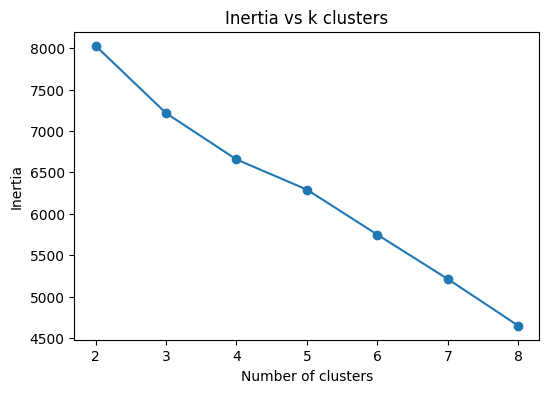

In [16]:
# Plot inertia vs k to find the optimal k using Elbow method

hdata.find_kmeans_k(
    data = subset_top10,
    key = "X",
    kind = "trajectory",
    trajectory_id = top_20_traj,
    max_clusters = 8
)

Based on the resulting plot, $k$=4 might be a reasonable choice in this case.

Now, we can run KMeans on the top 20 Highly Dynamic Trajectories (HDTs) that we found earlier. However, note that since KMeans does not operate directly on the pre-computed similarity/distance matrix, but rather on the raw feature space, it requires the raw vectors to compute its own internal Euclidean distances for clustering. Therefore, we would need to provide raw information to the `cluster_kmeans` function instead of the similarity matrix directly.

The resulting cluster labels are stored back into the original `hdata` object.

In [11]:
# Cluster the top 20 trajectories (HDT) using KMeans

hdata.cluster_kmeans(
        data = subset_top10,
        key = "X",
        kind = "trajectory",
        trajectory_id = top_20_traj,
        k = 4
    )

Cluster "kmeans_k4_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_ntr_gene', 'correlation_X_cell', 'correlation_X_trajectory']
  clusters: ['kmeans_k4_trajectory']
  embeddings: []
  trajectories: Yes

In [7]:
# Inspect the KMeans results to see which trajectory belongs to which cluster

cl_kmeans_traj20 = hdata.clusters["kmeans_k4_trajectory"]
cl_kmeans_traj20

traj_884    0
traj_194    3
traj_157    2
traj_797    2
traj_926    0
traj_160    3
traj_252    1
traj_709    2
traj_349    3
traj_866    2
traj_860    0
traj_29     1
traj_298    1
traj_170    3
traj_68     0
traj_531    3
traj_56     1
traj_617    1
traj_441    3
traj_381    3
Name: kmeans_k4_trajectory, dtype: int32

With the clustering results, we can visualize the contents of each trajectory cluster in two ways:
1. the regulation of a **specific gene** over time 
1. the **mean** across genes over time

In each subplot, the changes in gene expression values are plotted against the trajectory timepoints. The thick dotted line represents the cluster mean, whereas the individual line represents each individual trajectory in the cluster. The final subplot on the right overlays all cluster means for comparison. 

The visualization of the clusters allows us to examine the behaviour of why certain trajectories are grouped together. 

Recall that we used the top 10 HVGs for the trajectory clustering.

Top 10 HVGs: ['YOD1', 'SGK1', 'PARD6B', 'SMAD7', 'KLF6', 'KLF10', 'CEBPD', 'PLK2', 'ADM', 'GRPEL2']

In the first example, we shall visualize how the gene `YOD1` is regulated over time across all trajectories in the cluster to see if they share a coherent pattern.

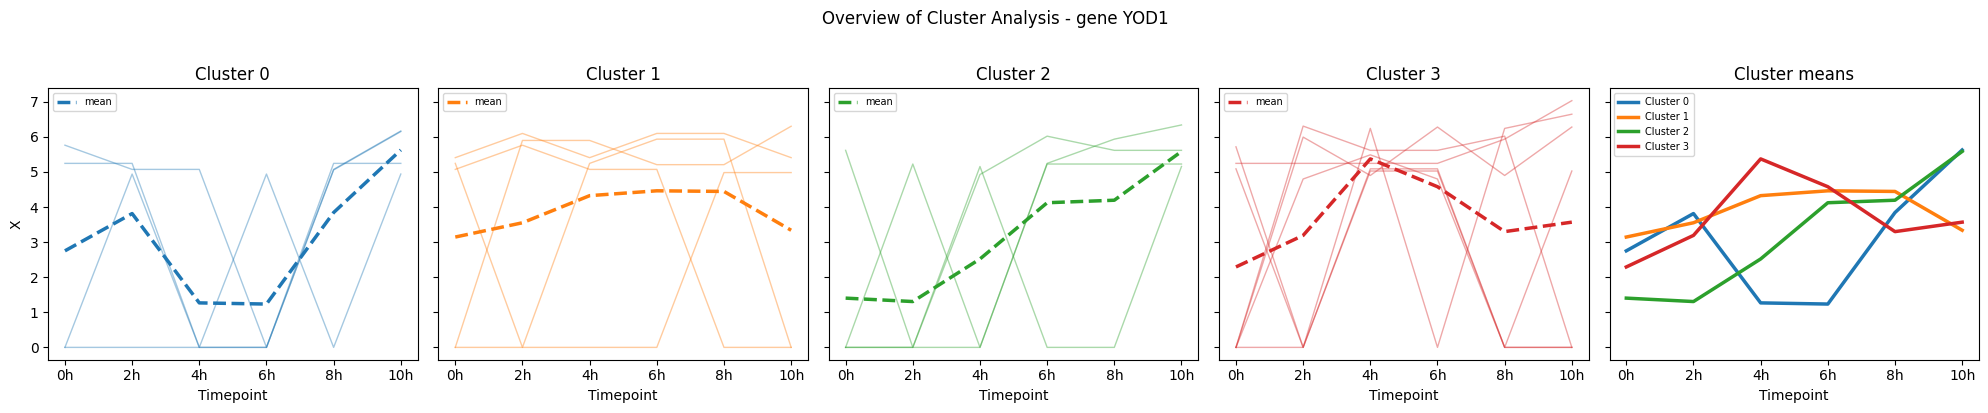

In [16]:
# Visualize gene YOD1 in trajectories cluster and the cluster mean

hda.visualize.line(
    data=subset_top10,
    cluster=cl_kmeans_traj20,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj,
    gene_sym="YOD1"
)

To further understand why certain trajectories cluster together, plotting the **per-cluster heatmap** on the mean gene expression across trajectories against trajectory timepoint provides an overview on the transcriptional program and shared behaviour within each cluster.

In [8]:
# Visualize per-cluster heatmap

hda.visualize.heatmap_cluster(
    data=subset_top10,
    cluster=cl_kmeans_traj20,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj
)

### Hierarchical Clustering

The second clustering algorithm we'll explore is hierarchical clustering, or more specifically agglomerative clustering, which is a bottom-up clustering approach. 

Since hierarchical clustering is capable of working on pre-computed similarity/distance matrix, we can now use the trajectory correlation similarity matrix `sim_traj20` obtained earlier to run hierarchical clustering. Recall the [trajectory-trajectory correlation similarity heatmap](###-Trajectory-trajectory-similarity) in Section 2, the dendograms above the heatmap is already a form of agglomerative clustering. We can now choose to form clusters either by setting $t$ threshold distance to "cut" the dendogram horizontally, or by setting a fixed $k$ number of clusters.

In [14]:
# Cluster the top 20 trajectories (HDT) using Hierarchical Clustering - Agglomerative 

hdata.cluster_hierarchical(
        sim = sim_traj20,                                 
        kind = "trajectory",
        k = 4
    )

Cluster "hierarchical_k4_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_ntr_gene', 'correlation_X_cell', 'correlation_X_trajectory']
  clusters: ['kmeans_k4_trajectory', 'hierarchical_k4_trajectory']
  embeddings: []
  trajectories: Yes

In [15]:
cl_hier_traj20 = hdata.clusters["hierarchical_k4_trajectory"]

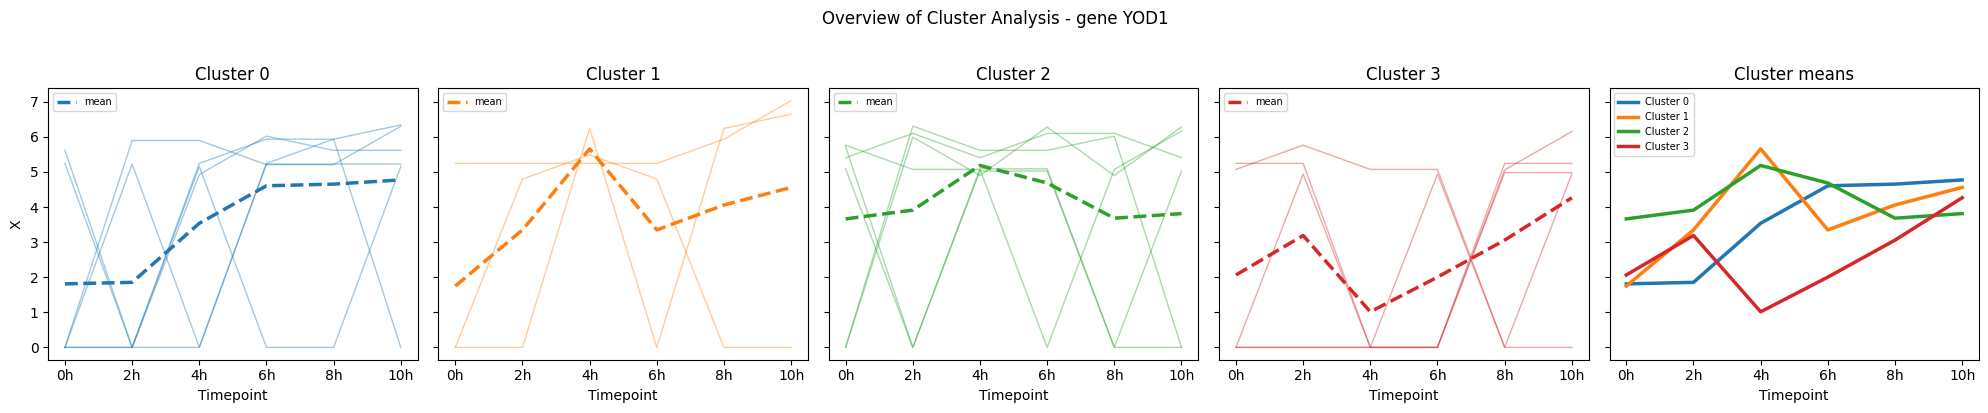

In [23]:
# Visualize gene YOD1 in trajectories cluster and the cluster mean

hda.visualize.line(
    data=subset_top10,
    cluster=cl_hier_traj20,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj,
    gene_sym="YOD1"
)

In [17]:
# Visualize per-cluster heatmap

hda.visualize.heatmap_cluster(
    data=subset_top10,
    cluster=cl_hier_traj20,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj
)

### Graph-based Clustering

The final clustering algorithm we'll explore is graph-based clustering, or more specifically Spectral Clustering in this case. 

Unlike KMeans, whose decision boundary is linear, spectral clustering groups data points based on their connectivity. This helps in identifying clusters with complex or non-convex shapes that KMeans would struggle to separate. It works by converting the similarity matrix into a graph Laplacian matrix $L$, extracting its eigenvectors, and then applying KMeans in this lower-dimensional eigenspace.

With that, similar to hierarchical clustering, we can make use of the trajectory correlation similarity matrix `sim_traj20` obtained earlier to run spectral clustering. 

In [18]:
# Cluster the top 20 trajectories (HDT) using Graph-based Clustering - Spectral

hdata.cluster_spectral(
        sim = sim_traj20,                                               
        kind = "trajectory",
        k = 4
    )

Cluster "spectral_k4_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_ntr_gene', 'correlation_X_cell', 'correlation_X_trajectory']
  clusters: ['kmeans_k4_trajectory', 'hierarchical_k4_trajectory', 'spectral_k4_trajectory']
  embeddings: []
  trajectories: Yes

In [19]:
c1_spec_traj20 = hdata.clusters["spectral_k4_trajectory"]

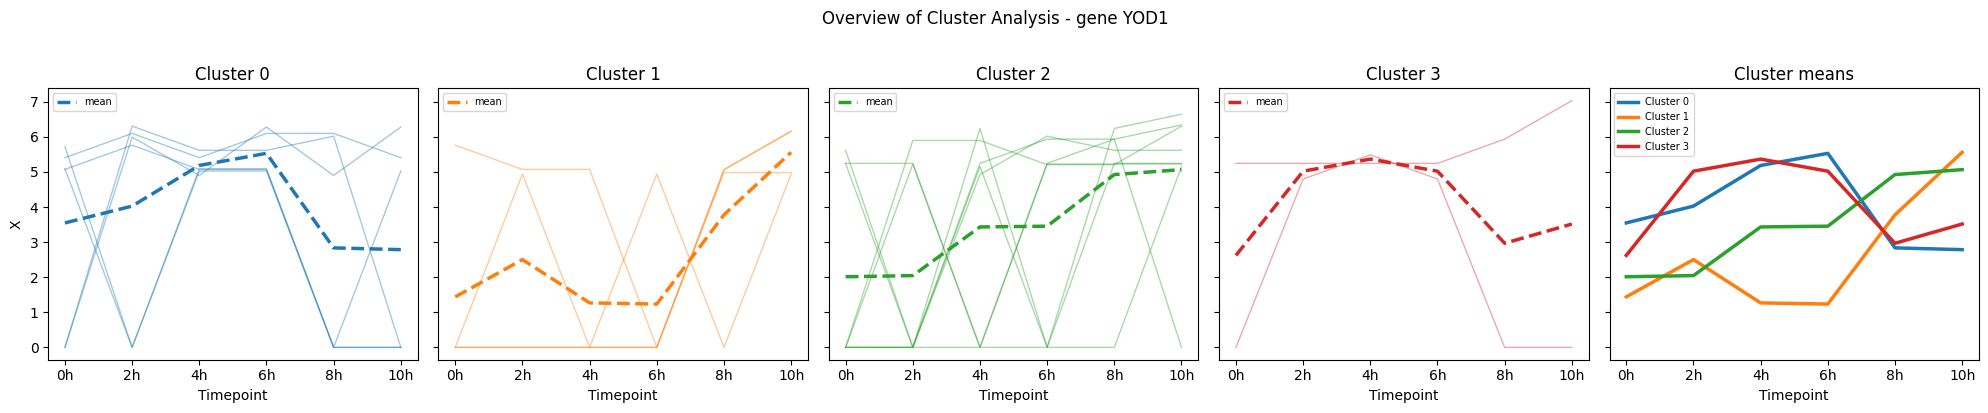

In [26]:
# Visualize gene YOD1 in trajectories cluster and the cluster mean

hda.visualize.line(
    data=subset_top10,
    cluster=c1_spec_traj20,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj,
    gene_sym="YOD1"
)

In [20]:
# Visualize per-cluster heatmap

hda.visualize.heatmap_cluster(
    data=subset_top10,
    cluster=c1_spec_traj20,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj
)

---

## 4. Dimensionality reduction algorithms

In the previous section, we saw how to cluster the trajectories using various clustering algorithms. Another way to visualize clusters in 2D is through dimensionality reduction.

This section of the tutorial is a continuation of the biological use case from [Section 2](##-2.-Distance-functions-for-dynamic-models-and-heatmaps) and builds on the concepts from [Section 2](##-2.-Distance-functions-for-dynamic-models-and-heatmaps) & [Section 3](##-3.-Clustering-algorithms). Here, we explore the dimensionality reduction algorithms such as:

- [Principle Component Analysis (PCA)](###-Principle-Component-Analysis-(PCA))
- [Multidimensional Scaling (MDS)](###-Multidimensional-Scaling-(MDS))
- [PCA-based cluster](###-PCA-based-cluster)

Note that for applications on dimensionality reduction, only the following combinations with Clustering methods are allowed.

Quick summary:

| Input | Clustering | Dimension Reduction |
| -- | -- | -- |
| raw vectors | KMeans | PCA |
| similarity matrix | Hierarchical (Agglomerative) | MDS |
| similarity matrix | Graph-based (Spectral) | MDS |

### Principle Component Analysis (PCA)

PCA works on the actual feature space to find the directions of the maximum variance in the raw trajectory vectors via eigendecomposition of the covariance matrix. Therefore, we need to provide raw information to the `reduce_pca` function instead of the similarity matrix directly. 

Here, we use PCA to project the clustered top 20 trajectory vectors (HDTs) into a 2-dimensional space, with Principle Component 1 on the x-axis and Principle Component 2 on the y-axis, visualizing each trajectory as a point on the scatter plot. The points are coloured according to the clusters identified by KMeans in [Section 3 KMeans](###-KMeans).

In [27]:
# Reduce the dimensions into 2D using PCA 

hdata.reduce_PCA(
    data = subset_top10,
    key = "X",
    kind = "trajectory",
    trajectory_id = top_20_traj,
)

PCA embedding "pca_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_ntr_gene', 'correlation_X_cell', 'correlation_X_trajectory']
  clusters: ['kmeans_k4_trajectory', 'hierarchical_k4_trajectory', 'spectral_k4_trajectory']
  embeddings: ['pca_trajectory']
  trajectories: Yes

In [28]:
# cl_kmeans_traj20 = hdata.clusters["kmeans_k4_trajectory"]
em_pca_traj20 = hdata.embeddings["pca_trajectory"]

Once the PCA embeddings are created, we can now visualize the KMeans clusters of the top 20 HDTs as a scatter plot projected by PCA.

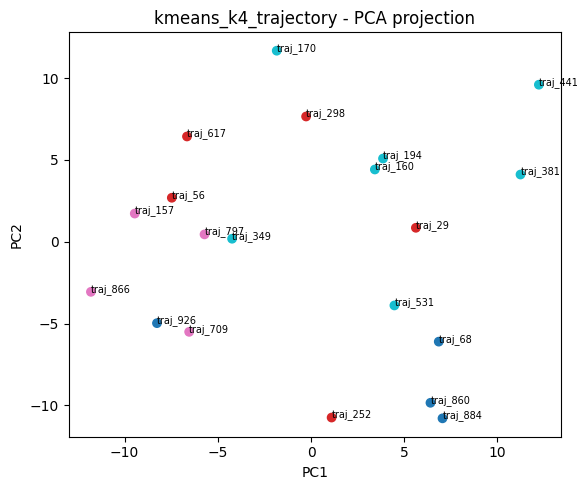

In [29]:
# Visualize the KMeans clusters as a scatter plot under PCA

hda.visualize.scatter(
    cluster=cl_kmeans_traj20,
    embedding=em_pca_traj20,
    reduction="PCA",
    show_label=True
)

### Multidimensional Scaling (MDS)

MDS operates directly on a matrix of pairwise distances or similarities to project data points into a lower-dimensional space. This makes it a natural dimensionality reduction method for our biological use case, as we already have the similarity matrix computed and stored in the original data object.

MDS can be used to visualize each trajectory as a point on a 2D scatter plot, with MDS1 on the x-axis and MDS2 on the y-axis. The points are coloured according to the clusters identified by the clustering algorithms from [Section 3 Hierarchical](###-Hierarchical-Clustering) and [Section 3 Graph-based](###-Graph-based-Clustering).

As an example, let's visualize the results from Hierarchical Clustering on the top 20 trajectory vectors (HDTs) on a scatter plot projected into 2D via MDS.

In [30]:
# Reduce the dimensions into 2D using MDS

hdata.reduce_MDS(
    sim = sim_traj20,
    kind = "trajectory"
)

MDS embedding "mds_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_ntr_gene', 'correlation_X_cell', 'correlation_X_trajectory']
  clusters: ['kmeans_k4_trajectory', 'hierarchical_k4_trajectory', 'spectral_k4_trajectory']
  embeddings: ['pca_trajectory', 'mds_trajectory']
  trajectories: Yes

In [31]:
# cl_hier_traj20 = hdata.clusters["hierarchical_k4_trajectory"]
em_mds_traj20 = hdata.embeddings["mds_trajectory"]

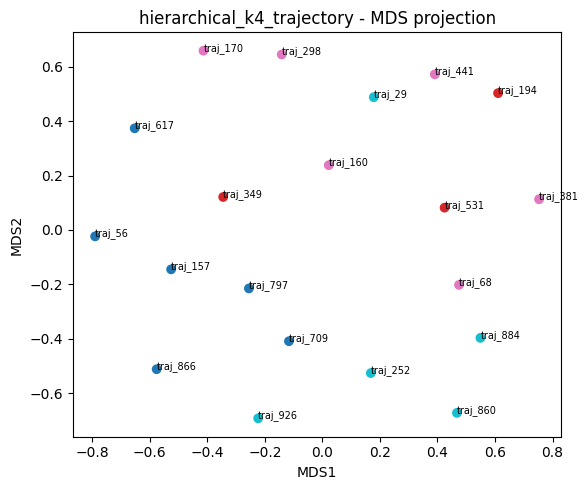

In [32]:
# Visualize the hierarchical clusters as a scatter plot under MDS

hda.visualize.scatter(
    cluster=cl_hier_traj20,
    embedding=em_mds_traj20,
    reduction="MDS",
    show_label=True
)

### PCA-based cluster

#### Cell

First, we will analyze the differences between expression-distance clusters compared to PCA-based clusters on <b>cells</b>. This is illustrated with an example using 2000 HVGs and 600 cells.

In [3]:
top_hvg = hdata.get_highly_variable_genes(n=2000)
cells_hvg = hdata.get_timepoint_cells(n=100)     # 100 x 6tp = 600 cells

# Initialize a temporary subset object for the selected cells 
subset_cells_ = hdata[top_hvg, cells_hvg]    # 2000 genes x 600 cells

<b>1. Expression-distance clusters</b>

gene x cell expression matrix -> distance matrix -> cluster 

Similarity "correlation_X_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_exp_dist" stored! 



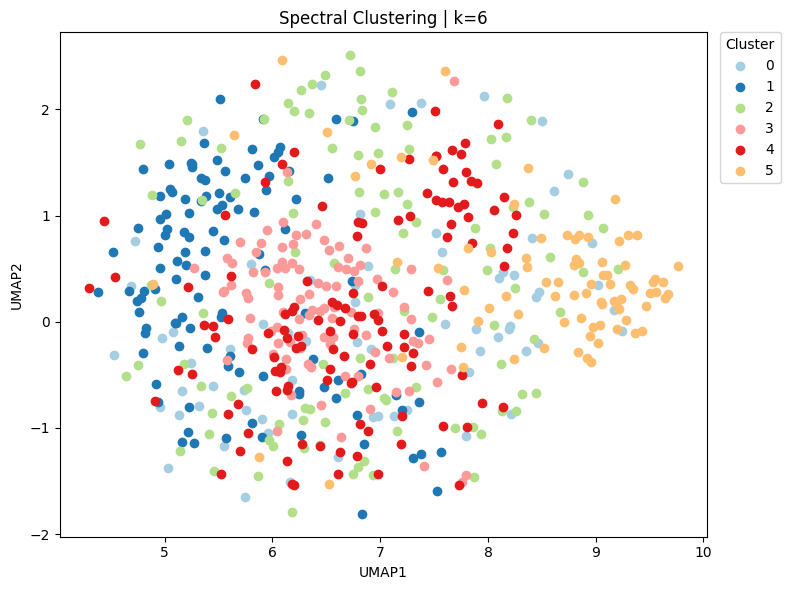

In [4]:
# Compute cell-cell similarity of the selected cells using normalized gene expression values 
hdata.compute_similarity(
    data=subset_cells_,
    key="X",
    kind="cell",
    method="correlation"
)

sim1 = hdata.similarities["correlation_X_cell"]

# Cluster the cells using Spectral Clustering
hdata.cluster_spectral(
        sim = sim1,                                 
        kind = "cell",
        k = 6
    )

cl1 = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data = subset_cells_,
    key = "X",
    kind = "cell",
    id = "exp_dist"
)

em1 = hdata.embeddings["umap_cell_exp_dist"]

# Visualize 
hda.visualize.scatter(
    cluster=cl1,
    embedding=em1,
    title="Spectral Clustering | k=6",
    show_label=False
)

In [ ]:
score1 = hdata.calc_cl_silhouette_score(
        cl=cl1, 
        precomputed=True, 
        sim=sim1
        )

<b>2. PCA-based clusters</b>

gene x cell expression matrix -> PCA (cell x PC) -> distance matrix -> cluster

In [5]:
# Example with 20 PCs

# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=20             # pc=20
)

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell']
  similarities: ['correlation_X_cell']
  clusters: ['spectral_k6_cell']
  embeddings: ['umap_cell_exp_dist']
  trajectories: Yes

Similarity "correlation_pca_cell_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc20" stored! 



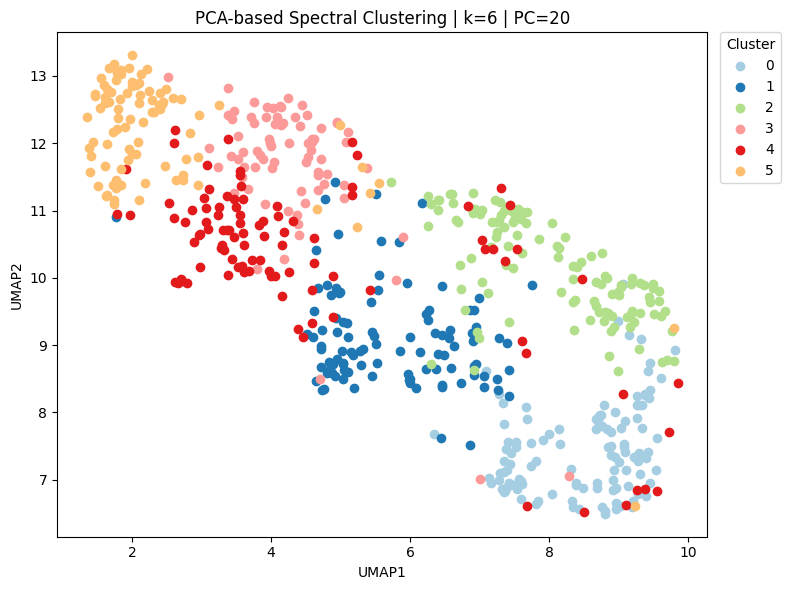

In [6]:
# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

sim2 = hdata.similarities["correlation_pca_cell_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim2,
    kind="cell",
    k=6
)

cl2 = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id="pc20"
)

em2 = hdata.embeddings["umap_cell_pc20"]

# Visualize 
hda.visualize.scatter(
    cluster=cl2,
    embedding=em2,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

In [ ]:
score2 = hdata.calc_cl_silhouette_score(
        cl=cl2, 
        precomputed=True, 
        sim=sim2
        )

<b>3. Compare PCA-based clusters with different PCs</b>

We can repeat the same steps for different PCs, such as PC=5 or PC=50, to see how sensitive the results changes based on the PC used. The image below shows an overall comparison of the clusters between Expression-distance cluster and PCA-based cluster on PC 5, 20, and 50.

![img1aa](temp/img1aa.jpg)

Observations
- PC 5: Cells grouped into broad, coarse clusters as distance is dominated by top signals. Might be over-simplifying real substructure
- PC 50: Clusters start to blur and overlap. Extra PCs contribute to noise dimensions and dilutes the real signal in the distance matrix

<b>4. Filtering PCA-based cluster plot on Total RNA</b>

With an interactive UMAP filtering, one can select how to colour the plot based on the following possible criterias:

- All clusters
- One specific cluster
- One specific gene
- One specific timepoint
- One specific gene + One specific timepoint

The examples below uses the UMAP filtering on the cell PCA-based clustering plot for PC=20.

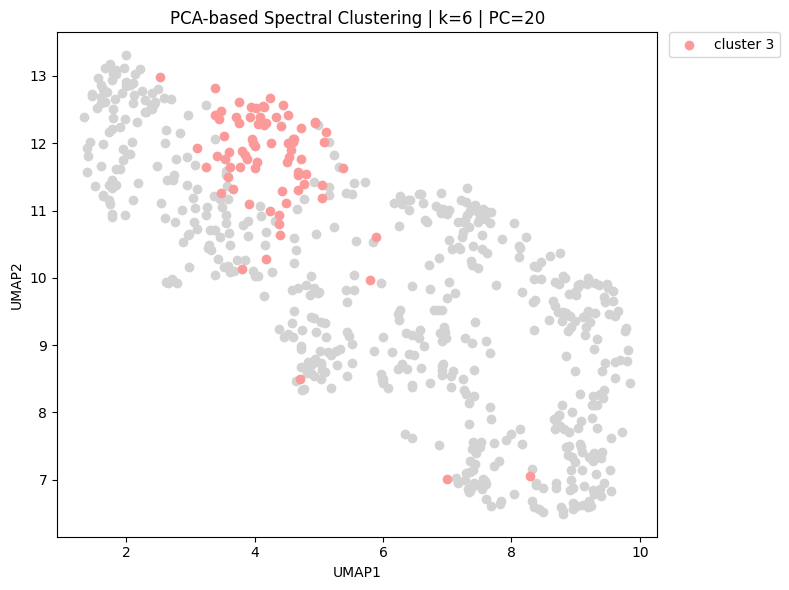

In [7]:
# One specific cluster

hda.visualize.scatter(
    cluster=cl2,
    embedding=em2, 
    highlight=3,            # Cluster number 3
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    )

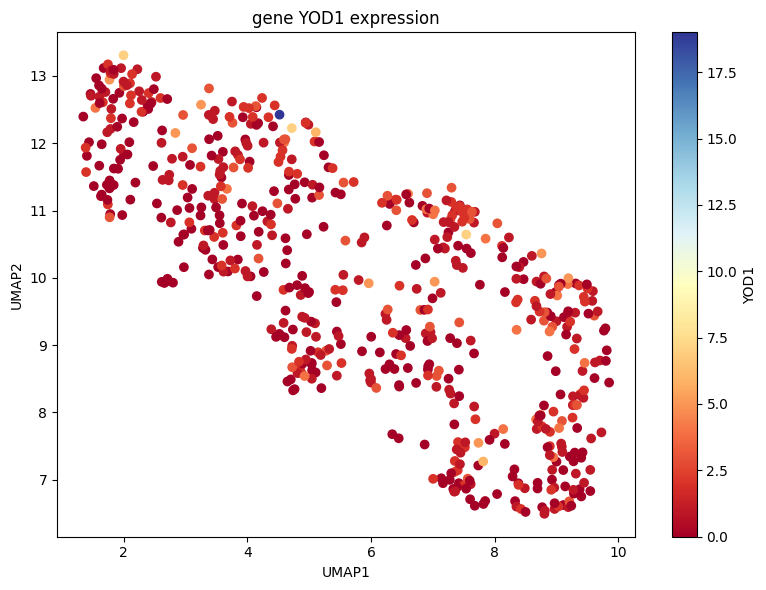

In [ ]:
# One specific gene

g1 = subset_cells_.get_gene_expression('YOD1')      # HVG

hda.visualize.scatter(
    embedding=em2, 
    values=g1,                      # gene as value (continuous color)
    legend_label="YOD1",
    title="gene YOD1 expression"
    )

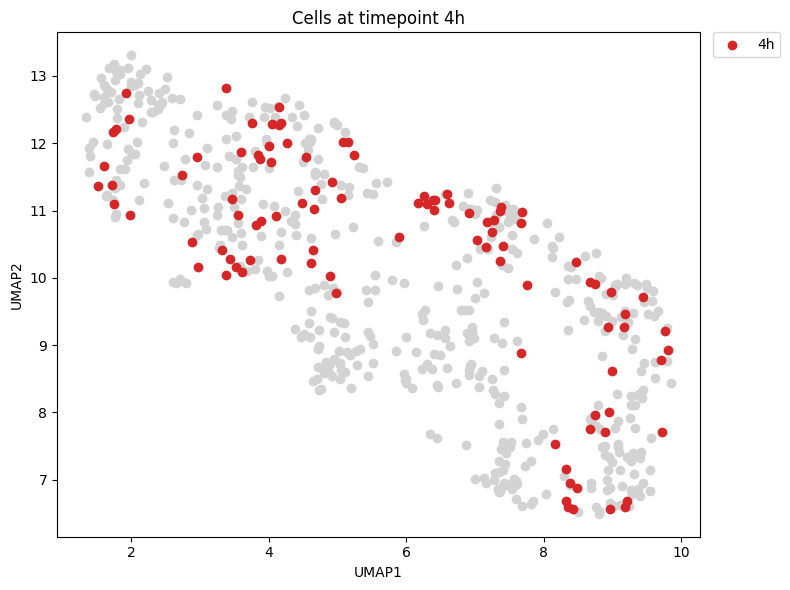

In [9]:
# One specific timepoint

time_mask = subset_cells_.obs["time"] == "4h" 

hda.visualize.scatter(
    embedding=em2, 
    mask=time_mask,         # timepoint as mask 
    legend_label="4h",
    title="Cells at timepoint 4h"
    )

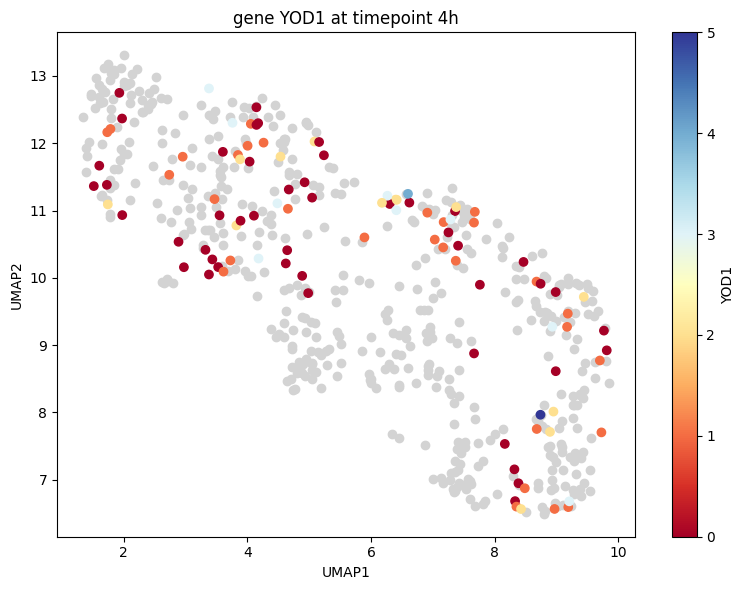

In [10]:
# One specific gene + One specific timepoint

hda.visualize.scatter(
    embedding=em2, 
    values=g1,
    mask=time_mask,
    legend_label="YOD1",
    title="gene YOD1 at timepoint 4h"
    )

<b>5. Compare PCA-based clusters on Total RNA vs New RNA</b>

New RNA is the amount of gene expression X multiplied by the NTR value, which yields the new RNA measure. 

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc20" stored! 



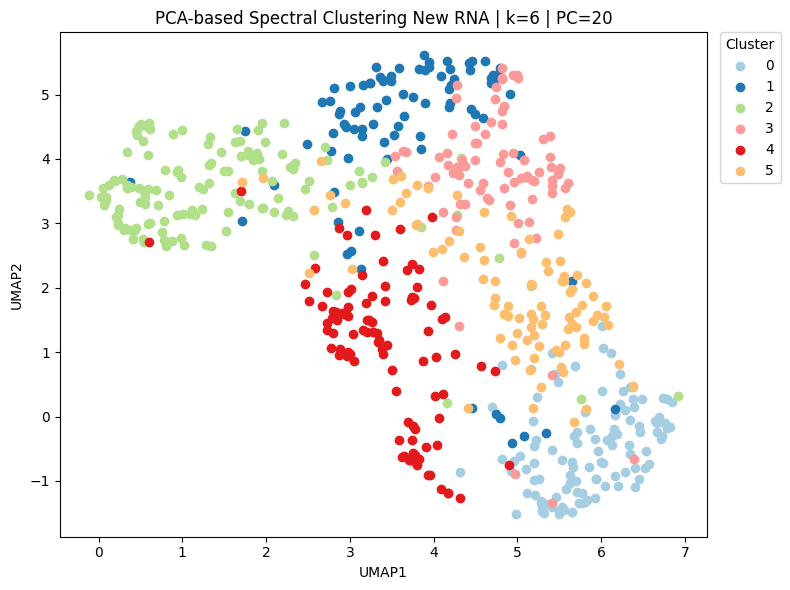

In [11]:
# PCA on new RNA
hdata.compute_PCA(
    data=subset_cells_,
    key="new_rna",          # use new RNA
    kind="cell",
    n_pc=20                 # pc=20
)

pc_matrix = hdata.layers["pca_cell"]  

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

sim3 = hdata.similarities["correlation_pca_cell_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim3,
    kind="cell",
    k=6
)

cl3 = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id = "pc20"
)

em3= hdata.embeddings["umap_cell_pc20"] 

# Visualize 
hda.visualize.scatter(
    cluster=cl3,
    embedding=em3,
    title="PCA-based Spectral Clustering New RNA | k=6 | PC=20",
    show_label=False
)

In [ ]:
score3 = hdata.calc_cl_silhouette_score(
        cl=cl3, 
        precomputed=True, 
        sim=sim3
        )

The image below shows the results for PCA-based clusters on Total RNA vs New RNA using 20 PCs.

![img1bb](temp/img1bb.jpg)

#### Trajectories

Next, we can also analyze the differences between PCA-based clusters vs non-PCA-based clusters on <b>trajectories</b>. This is illustrated with an example using 2000 HVGs and 300 HDTs.

In [ ]:
# Note: restart kernel before running, hdata might be storing previous results

top_hvg = hdata.get_highly_variable_genes(n=2000)

# Initialize a temporary subset object for the selected cells 
subset_traj_ = hdata[top_hvg, :]    # 2000 genes x allcells (keep all cells available when using get_highly_dynamic_trajectories)

# Get top HDTs
top_traj = subset_traj_.get_highly_dynamic_trajectories(n=300)

<b>1. Concatenate first → PCA</b>

Trajectory × (gene × position) matrix    

↓ PCA 

Trajectory × PC matrix            

↓ similarity + spectral clustering

Clusters

In [5]:
# PCA on trajectory × (gene*timepoints) matrix
hdata.compute_PCA(
    data=subset_traj_,
    key="X",
    kind="trajectory",
    n_pc=20,
    trajectory_id=top_traj
)

PCA matrix trajectory x 20 PCs stored in HDAData.layers["pca_trajectory"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_trajectory']
  similarities: []
  clusters: []
  embeddings: []
  trajectories: Yes

Similarity "correlation_pca_trajectory_trajectory" stored! 

Cluster "spectral_k6_trajectory" stored! 

UMAP embedding "umap_trajectory_exp_dist" stored! 



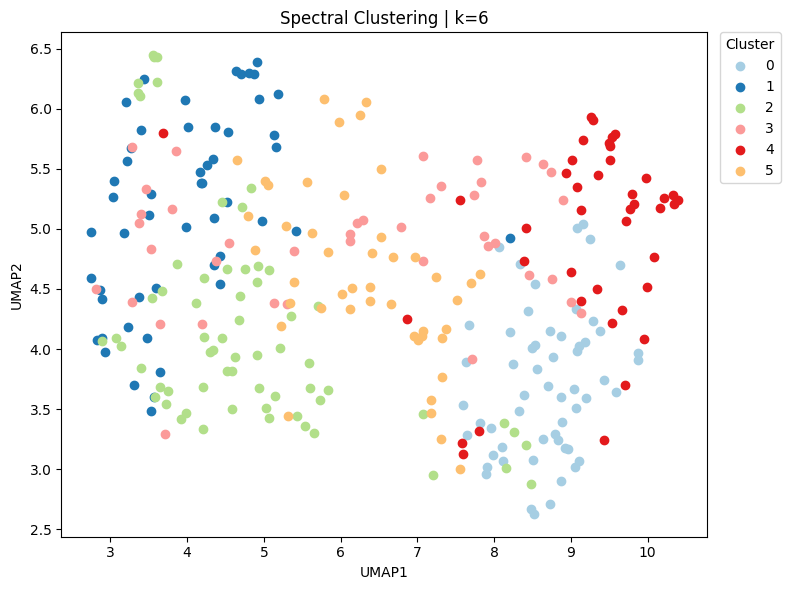

In [ ]:
hdata.compute_similarity(
    data=subset_traj_,
    key="pca_trajectory",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

sim4 = hdata.similarities["correlation_pca_trajectory_trajectory"]

# Cluster using Graph-based Clustering - Spectral
hdata.cluster_spectral(
        sim = sim4,                                               
        kind = "trajectory",
        k = 6
    )

cl4 = hdata.clusters["spectral_k6_trajectory"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_trajectory",
    kind="trajectory",
    trajectory_id=top_traj,
    id = "exp_dist"
)

em4 = hdata.embeddings["umap_trajectory_exp_dist"]

# Visualize 
hda.visualize.scatter(
    cluster=cl4,
    embedding=em4,
    title="Spectral Clustering | k=6",
    show_label=False
)

In [ ]:
score4 = hdata.calc_cl_silhouette_score(
        cl=cl4, 
        precomputed=True, 
        sim=sim4
        )

<b>2. PCA first → Concatenate</b>

Cell × gene matrix         

↓ PCA on cells

Cell × PC matrix      

↓ build trajectory vectors using PC scores

Trajectory × PC*timepoints matrix    

↓ similarity + spectral clustering

Clusters

In [7]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_traj_,
    key="X",
    kind="cell",
    n_pc=20
)

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_trajectory', 'pca_cell']
  similarities: ['correlation_pca_trajectory_trajectory']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist']
  trajectories: Yes

Similarity "correlation_pca_cell_trajectory" stored! 

Cluster "spectral_k6_trajectory" stored! 

UMAP embedding "umap_trajectory_pca_based" stored! 



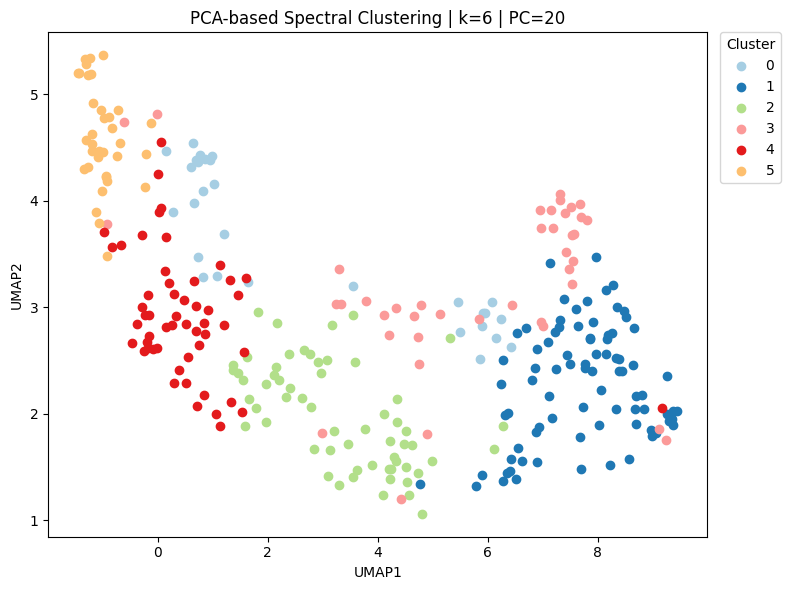

In [8]:
# Compute traj-traj distance matrix in PC space
hdata.compute_similarity(
    data=subset_traj_,
    key="pca_cell",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

sim5 = hdata.similarities["correlation_pca_cell_trajectory"]

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim5,
    kind="trajectory",
    k=6
)

cl5 = hdata.clusters["spectral_k6_trajectory"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_cell",
    kind="trajectory",
    trajectory_id=top_traj,
    id = "pca_based"
)

em5 = hdata.embeddings["umap_trajectory_pca_based"]

# Visualize 
hda.visualize.scatter(
    cluster=cl5,
    embedding=em5,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

In [ ]:
score5 = hdata.calc_cl_silhouette_score(
        cl=cl5, 
        precomputed=True, 
        sim=sim5
        )

<b>3. Compare PCA-based clusters on Total RNA vs New RNA</b>

Repeat the two methods on New RNA:
- Concatenate first → PCA
- PCA first → Concatenate

Concatenate first → PCA

PCA matrix trajectory x 20 PCs stored in HDAData.layers["pca_trajectory"] 

Similarity "correlation_pca_trajectory_trajectory" stored! 

Cluster "spectral_k6_trajectory" stored! 

UMAP embedding "umap_trajectory_exp_dist" stored! 



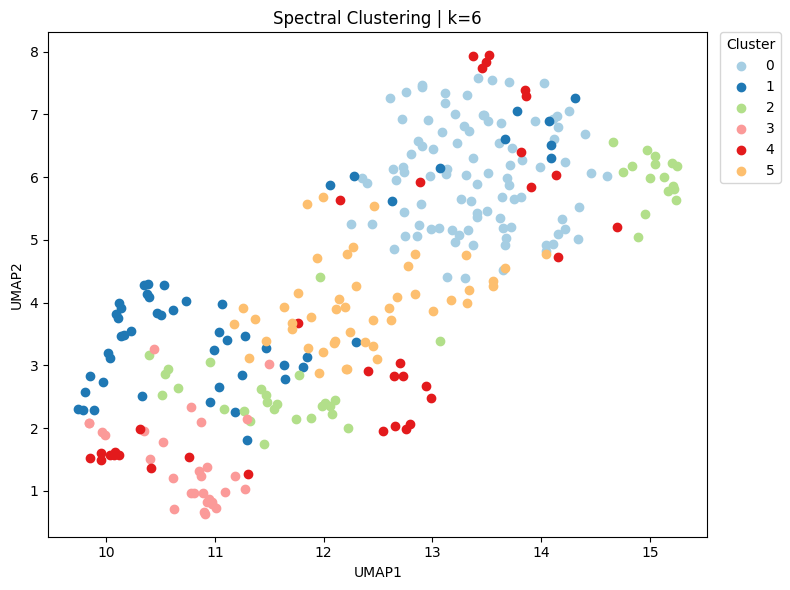

In [ ]:
hdata.compute_PCA(
    data=subset_traj_,
    key="new_rna",
    kind="trajectory",
    n_pc=20,
    trajectory_id=top_traj
)

hdata.compute_similarity(
    data=subset_traj_,
    key="pca_trajectory",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

sim6 = hdata.similarities["correlation_pca_trajectory_trajectory"]

hdata.cluster_spectral(
        sim = sim6,                                               
        kind = "trajectory",
        k = 6
    )

cl6 = hdata.clusters["spectral_k6_trajectory"]

hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_trajectory",
    kind="trajectory",
    trajectory_id=top_traj,
    id = "exp_dist"
)

em6 = hdata.embeddings["umap_trajectory_exp_dist"]

hda.visualize.scatter(
    cluster=cl6,
    embedding=em6,
    title="Spectral Clustering | k=6",
    show_label=False
)

In [ ]:
score6 = hdata.calc_cl_silhouette_score(
        cl=cl6, 
        precomputed=True, 
        sim=sim6
        )

PCA first → Concatenate

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_trajectory" stored! 

Cluster "spectral_k6_trajectory" stored! 

UMAP embedding "umap_trajectory_pca_based" stored! 



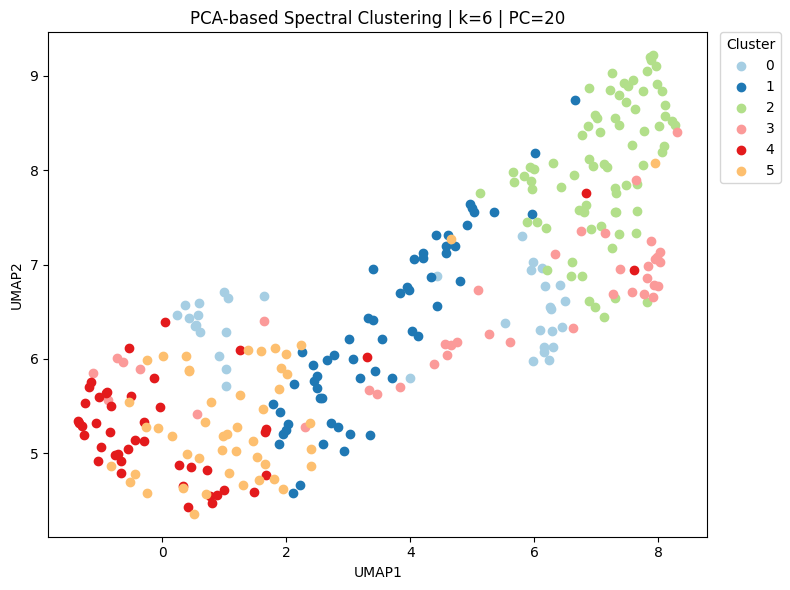

In [ ]:
hdata.compute_PCA(
    data=subset_traj_,
    key="new_rna",
    kind="cell",
    n_pc=20
)

hdata.compute_similarity(
    data=subset_traj_,
    key="pca_cell",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

sim7 = hdata.similarities["correlation_pca_cell_trajectory"]

hdata.cluster_spectral(
    sim=sim7,
    kind="trajectory",
    k=6
)

cl7 = hdata.clusters["spectral_k6_trajectory"]

hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_cell",
    kind="trajectory",
    trajectory_id=top_traj,
    id = "pca_based"
)

em7 = hdata.embeddings["umap_trajectory_pca_based"]

hda.visualize.scatter(
    cluster=cl7,
    embedding=em7,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

In [ ]:
score7 = hdata.calc_cl_silhouette_score(
        cl=cl7, 
        precomputed=True, 
        sim=sim7
        )

The image below shows an overview of the results for comparison.

![img2a](temp/img2a.jpg)